# SkinFind: Exploratory Data Analysis

## Project Overview

SkinFind is an information retrieval system for Indonesian beauty product reviews. This notebook explores the dataset before text preprocessing, search implementation, and retrieval evaluation.

## Objectives

1. Understand the dataset structure and data types.
2. Check data quality, missing values, and duplicate records.
3. Analyze review text lengths.
4. Explore sentiment labels for price, packaging, product, and aroma.
5. Identify findings that can guide the information retrieval system.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "produk_kecantikan.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("Figure directory:", FIGURE_DIR)

Project root: D:\STKI_Project
Dataset path: D:\STKI_Project\data\raw\produk_kecantikan.csv
Dataset exists: True
Figure directory: D:\STKI_Project\reports\figures


In [2]:
# Load the original dataset
df = pd.read_csv(DATA_PATH)

print("DATASET OVERVIEW")
print("=" * 50)
print(f"Number of reviews : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")
print(f"Memory usage      : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
display(df.dtypes.rename("Data Type").to_frame())

print("\nFIRST FIVE REVIEWS")
display(df.head())

DATASET OVERVIEW
Number of reviews : 3,960
Number of columns : 6
Memory usage      : 1.81 MB

COLUMN NAMES
['review_id', 'review_text', 'price', 'packaging', 'product', 'aroma']

DATA TYPES


,Data Type
review_id,int64
review_text,object
price,int64
packaging,int64
product,float64
aroma,int64



FIRST FIVE REVIEWS


,review_id,review_text,price,packaging,product,aroma
0,708,sunscreen termahal yang pernah gue beli ini ka...,-1,0,1.0,0
1,838,"ini enak banget dipakainya, enteng banget diwa...",0,0,1.0,0
2,1166,the description is quite right. produk ini ema...,0,0,1.0,1
3,1374,bisa untuk wajah dan badan dengan harga yang s...,1,1,1.0,0
4,1421,saya beli produk ini karena suka banget wangin...,-1,0,0.0,1


In [3]:
quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True),
})

print("DATA QUALITY REPORT")
display(quality_report)

print("Duplicate review IDs:", df["review_id"].duplicated().sum())
print("Duplicate review texts:", df["review_text"].duplicated().sum())
print(
    "Empty review texts:",
    df["review_text"].fillna("").str.strip().eq("").sum()
)

DATA QUALITY REPORT


,Data Type,Missing Values,Missing (%),Unique Values
review_id,int64,0,0.00,3960
review_text,object,0,0.00,3960
price,int64,0,0.00,3
packaging,int64,0,0.00,3
product,float64,1,0.03,3
aroma,int64,0,0.00,3


Duplicate review IDs: 0
Duplicate review texts: 0
Empty review texts: 0


,price,packaging,product,aroma
Negative,716,189,688,218
Neutral,2187,3324,659,3073
Positive,1057,447,2612,669


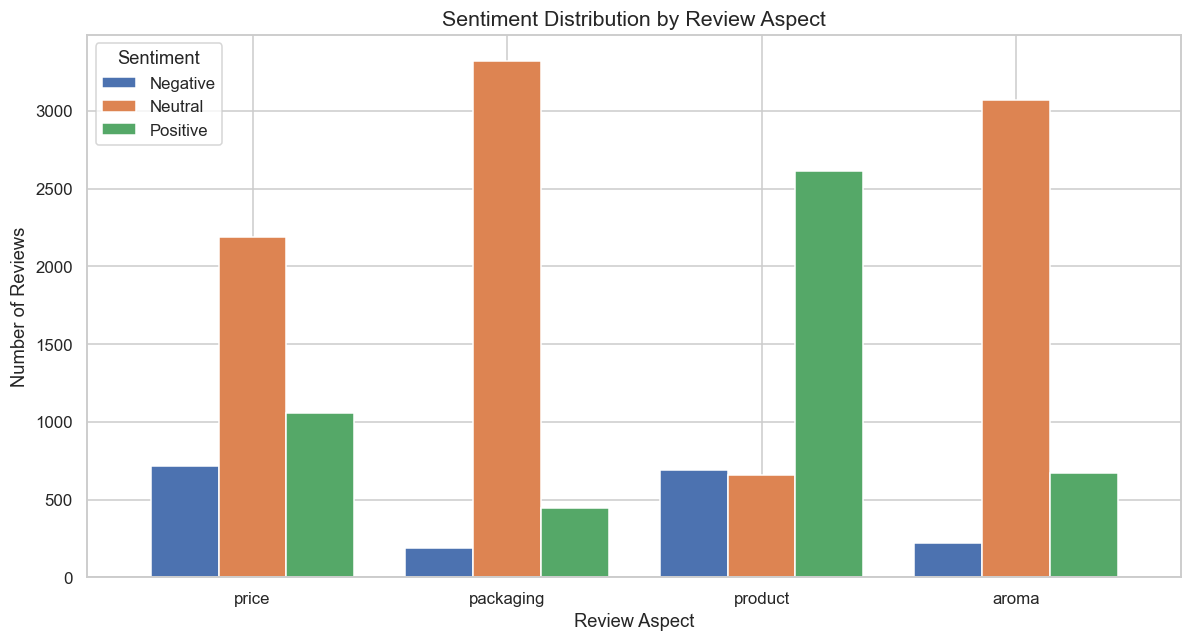

Figure saved to: D:\STKI_Project\reports\figures\sentiment_distribution.png


<Figure size 1100x550 with 0 Axes>

In [4]:
# Map numeric sentiment labels to readable names
sentiment_names = {
    -1: "Negative",
    0: "Neutral",
    1: "Positive",
}

aspect_columns = ["price", "packaging", "product", "aroma"]

# Count sentiment labels for each aspect
sentiment_counts = pd.DataFrame({
    aspect: df[aspect].map(sentiment_names).value_counts()
    for aspect in aspect_columns
}).reindex(["Negative", "Neutral", "Positive"])

display(sentiment_counts.fillna(0).astype(int))

# Create a comparison chart
ax = sentiment_counts.T.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Sentiment Distribution by Review Aspect", fontsize=14)
ax.set_xlabel("Review Aspect")
ax.set_ylabel("Number of Reviews")
ax.legend(title="Sentiment")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

sentiment_figure_path = FIGURE_DIR / "sentiment_distribution.png"
plt.savefig(sentiment_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", sentiment_figure_path)
sentiment_figure_path = FIGURE_DIR / "sentiment_distribution.png"
plt.savefig(sentiment_figure_path, dpi=300, bbox_inches="tight")

REVIEW TEXT LENGTH STATISTICS


,Characters
count,3960.00
mean,389.47
std,223.31
min,29.00
25%,254.00
50%,326.00
75%,444.00
max,3411.00



Shortest review:
one of my fav skin care serum

Longest review length: 3411 characters


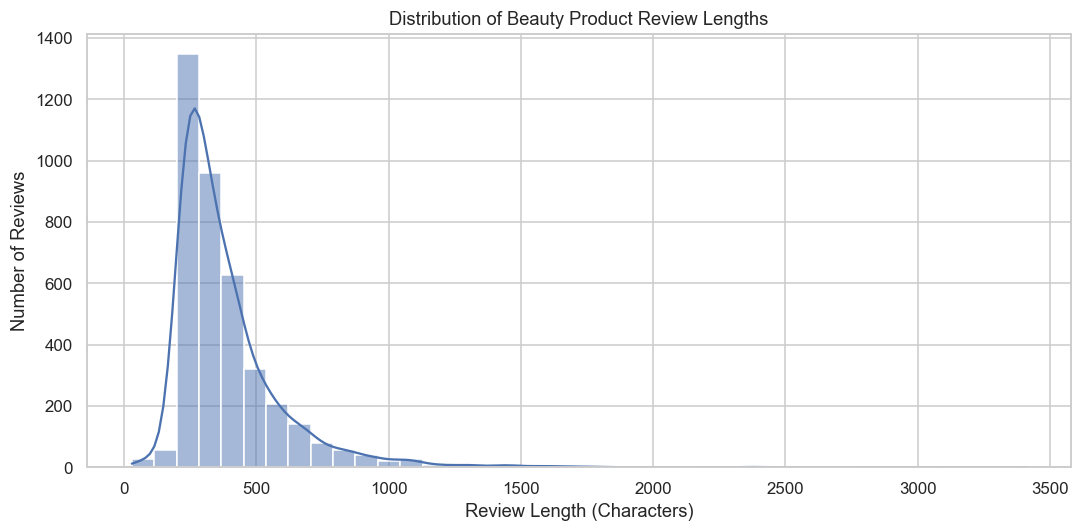

Figure saved to: D:\STKI_Project\reports\figures\review_length_distribution.png


In [5]:
# Calculate review text lengths
df["review_length"] = df["review_text"].astype(str).str.len()

# Summary statistics
length_summary = df["review_length"].describe().round(2)

print("REVIEW TEXT LENGTH STATISTICS")
display(length_summary.to_frame(name="Characters"))

print("\nShortest review:")
print(df.loc[df["review_length"].idxmin(), "review_text"])

print("\nLongest review length:", df["review_length"].max(), "characters")

# Create histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="review_length",
    bins=40,
    kde=True
)

plt.title("Distribution of Beauty Product Review Lengths")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")
plt.tight_layout()

length_figure_path = FIGURE_DIR / "review_length_distribution.png"
plt.savefig(length_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", length_figure_path)

## Analisis Panjang Teks Ulasan

Dataset ini terdiri dari 3.960 ulasan produk kecantikan. Rata-rata panjang ulasan adalah 389,47 karakter, sedangkan nilai mediannya adalah 326 karakter. Kuartil pertama menunjukkan panjang 254 karakter dan kuartil ketiga 444 karakter. Hal ini menunjukkan bahwa sebagian besar ulasan memiliki panjang antara 254 hingga 444 karakter.

Ulasan terpendek memiliki panjang 29 karakter, sedangkan ulasan terpanjang mencapai 3.411 karakter. Nilai rata-rata yang lebih tinggi daripada median menunjukkan bahwa distribusi panjang ulasan cenderung menceng ke kanan. Kondisi ini kemungkinan disebabkan oleh beberapa ulasan yang jauh lebih panjang dibandingkan ulasan lainnya.

Temuan ini menunjukkan bahwa panjang teks ulasan cukup bervariasi. Oleh karena itu, tahap prapemrosesan teks perlu mempertahankan informasi penting dari ulasan sekaligus mempersiapkan teks agar dapat digunakan secara efisien dalam sistem temu kembali informasi SkinFind.

## Ringkasan Temuan Eksplorasi Data

Berdasarkan hasil eksplorasi terhadap 3.960 ulasan produk kecantikan, diperoleh beberapa temuan utama:

1. **Kualitas data:** Dataset memiliki 3.960 baris dan 6 kolom. Tidak ditemukan nilai kosong pada teks ulasan, teks kosong, ID ulasan duplikat, maupun teks ulasan duplikat. Namun, terdapat satu nilai kosong pada aspek `product`.

2. **Distribusi sentimen:** Aspek `product` didominasi sentimen positif sebanyak 2.612 ulasan. Sebaliknya, aspek `packaging` didominasi sentimen netral sebanyak 3.324 ulasan. Aspek `price` dan `aroma` juga didominasi sentimen netral.

3. **Panjang teks:** Rata-rata panjang ulasan adalah 389,47 karakter, dengan median 326 karakter. Panjang ulasan bervariasi dari 29 hingga 3.411 karakter.

4. **Implikasi terhadap sistem:** Variasi panjang ulasan dan distribusi sentimen menunjukkan bahwa sistem SkinFind perlu melakukan prapemrosesan teks sebelum membangun fitur pencarian. Nilai sentimen yang kosong pada aspek `product` juga perlu ditangani secara tepat tanpa menghapus teks ulasan yang masih dapat digunakan.

### Kesimpulan

Eksplorasi awal menunjukkan bahwa dataset memiliki teks ulasan yang dapat digunakan untuk membangun sistem temu kembali informasi. Tahap berikutnya adalah melakukan prapemrosesan teks, membangun fitur pencarian menggunakan TF-IDF, dan mengevaluasi relevansi hasil pencarian.